# Polynomial Regression (simple version)

**Goal:** predict a car's fuel efficiency (`mpg`) from its `horsepower`.

Keep `mpg.csv` in the same folder as this notebook.

## Step 1: Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

## Step 2: Load the data

In [2]:
df = pd.read_csv("mpg.csv")
df = df.dropna()                       # remove rows with missing values

X = df[["horsepower"]]                 # input
y = df["mpg"]                          # output

X_sorted = X.sort_values("horsepower") # sorted copy, used only to draw smooth lines

df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


## Step 3: Plot the data

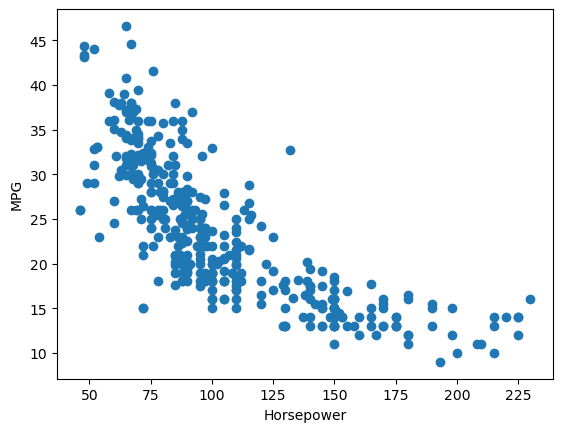

In [3]:
plt.scatter(X, y)
plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.show()

The data is **curved**, not straight.

## Step 4: Split into training and testing data

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Step 5: Try a straight line (linear regression)

Test score (R2): 0.5659681822256184


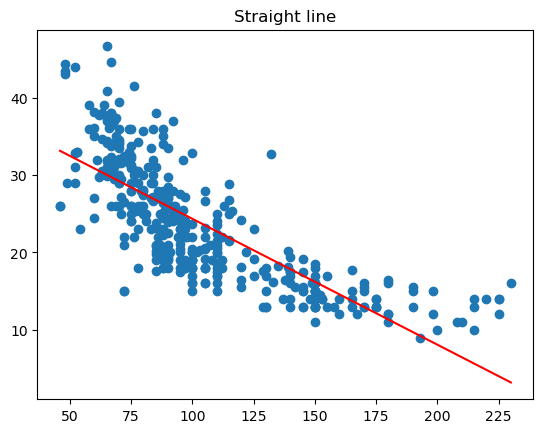

In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Test score (R2):", model.score(X_test, y_test))

plt.scatter(X, y)
plt.plot(X_sorted, model.predict(X_sorted), color="red")
plt.title("Straight line")
plt.show()

The straight line cannot follow the curve.

## Step 6: Try polynomial regression (degree 2)

A **pipeline** runs three steps in order:
1. `PolynomialFeatures` adds new columns: horsepower²
2. `StandardScaler` brings the columns to a similar size
3. `LinearRegression` fits the model

Test score (R2): 0.6391701147013312


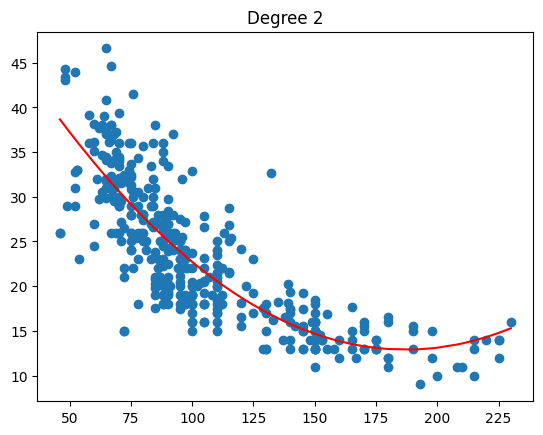

In [6]:
model = Pipeline([
    ("poly", PolynomialFeatures(degree=2)),
    ("scaler", StandardScaler()),
    ("linreg", LinearRegression())
])
model.fit(X_train, y_train)

print("Test score (R2):", model.score(X_test, y_test))

plt.scatter(X, y)
plt.plot(X_sorted, model.predict(X_sorted), color="red")
plt.title("Degree 2")
plt.show()

The curve bends and fits the data better. The score goes up.

## Step 7: Compare a few degrees

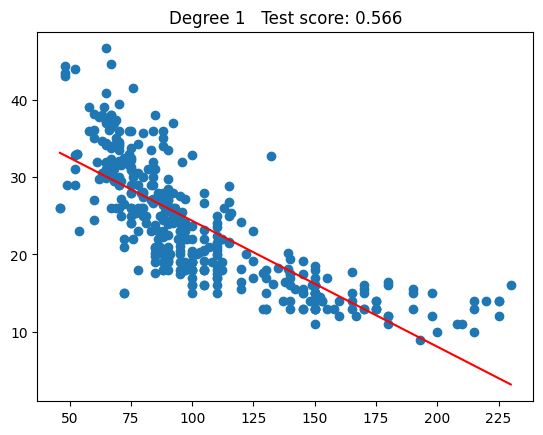

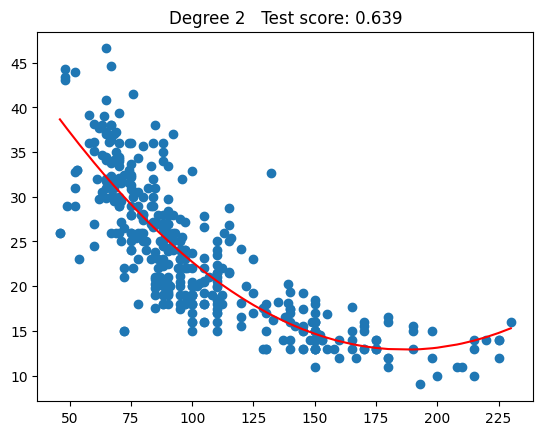

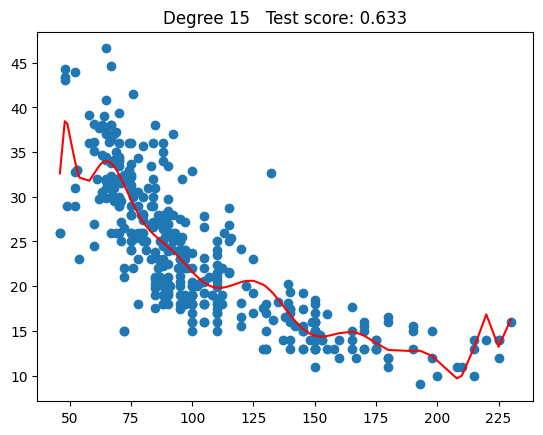

In [7]:
for d in [1, 2, 15]:
    model = Pipeline([
        ("poly", PolynomialFeatures(degree=d)),
        ("scaler", StandardScaler()),
        ("linreg", LinearRegression())
    ])
    model.fit(X_train, y_train)

    plt.scatter(X, y)
    plt.plot(X_sorted, model.predict(X_sorted), color="red")
    plt.title("Degree " + str(d) + "   Test score: " + str(round(model.score(X_test, y_test), 3)))
    plt.show()

- Degree 1: too simple (underfitting)
- Degree 2: good fit
- Degree 15: too wiggly (overfitting)

Which degree is best? Let **GridSearchCV** find out.

## Step 8: Find the best degree with GridSearchCV

GridSearchCV tries every degree in the list. For each one, it uses **5-fold cross-validation**
on the training data and keeps the degree with the best average score.

`"poly__degree"` means: the `degree` setting inside the step named `poly`.

In [8]:
model = Pipeline([
    ("poly", PolynomialFeatures()),
    ("scaler", StandardScaler()),
    ("linreg", LinearRegression())
])

degrees = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

grid = GridSearchCV(model, {"poly__degree": degrees}, cv=5)
grid.fit(X_train, y_train)

print("Best degree:", grid.best_params_)
print("Best cross-validation score (R2):", grid.best_score_)

Best degree: {'poly__degree': 2}
Best cross-validation score (R2): 0.6805904758396922


### Score for each degree

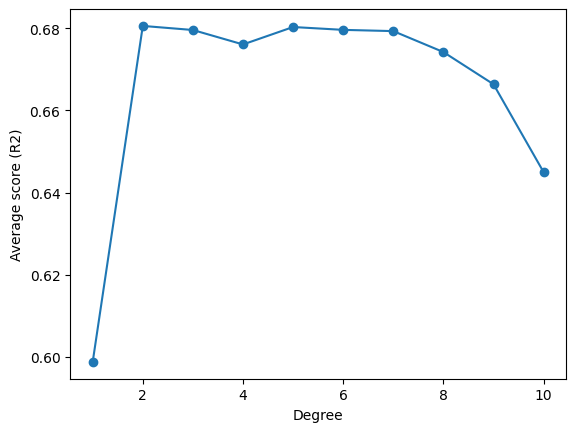

In [9]:
scores = grid.cv_results_["mean_test_score"]

plt.plot(degrees, scores, marker="o")
plt.xlabel("Degree")
plt.ylabel("Average score (R2)")
plt.show()

The score jumps from degree 1 to 2, then stops improving.

## Step 9: Test the best model on unseen data

Test score (R2): 0.6391701147013312


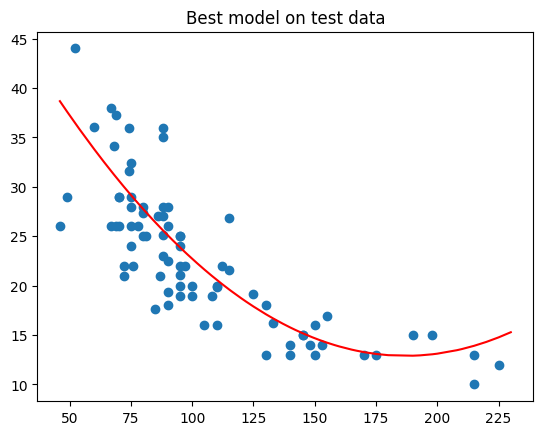

In [10]:
best_model = grid.best_estimator_

print("Test score (R2):", best_model.score(X_test, y_test))

plt.scatter(X_test, y_test)
plt.plot(X_sorted, best_model.predict(X_sorted), color="red")
plt.title("Best model on test data")
plt.show()

## Practice
1. Change `cv=5` to `cv=10`. Does the best degree change?
2. Use `weight` instead of `horsepower` as the input. What degree is best now?